# Phishing Detection with NLP: Enron, PhishTank and an Explainable Ensemble

**AI for Cybersecurity, Module 5 Lab** · Ruthvik Nath Bandari · Northeastern University

| Step | What happens |
|---|---|
| 1. Data and preprocessing | Real Enron corporate emails (legitimate) and synthetic phishing emails built from known attack patterns around real PhishTank URLs; NLTK tokenization, stop-word removal, stemming and TF-IDF; phishing-specific features |
| 2. Models | Naive Bayes (baseline), linear SVM and Random Forest, plus a stacked ensemble of a text model, a URL model and a metadata model; stratified cross-validation tuned for high recall; n-grams and named entity recognition |
| 3. Analysis | Confusion matrix, precision-recall curves, F1, top phishing indicators, an explainable risk dashboard, a test on **real-world** phishing examples, security recommendations and a threat intelligence summary |

**Data sources.** Enron Email Dataset (CMU, May 2015 release) and the PhishTank verified-online feed (Cisco Talos),
both downloaded inside the notebook. Real-world phishing examples for the final test come from a public Kaggle
phishing-email dataset. Everything is seeded (`SEED = 42`); a full *Runtime → Run all* takes about 20 minutes on a free Colab CPU, including the
443 MB Enron download.

## Step 1 · Data collection and text preprocessing

In [1]:
import os, re, io, time, tarfile, hashlib, email, random, warnings, urllib.request, json
from email import policy
from pathlib import Path
from collections import Counter
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

import nltk
for res in ["punkt_tab", "stopwords", "vader_lexicon", "words", "averaged_perceptron_tagger_eng", "maxent_ne_chunker_tab"]:
    nltk.download(res, quiet=True)
from nltk import word_tokenize, pos_tag
from nltk.corpus import stopwords, words as nltk_words
from nltk.stem import PorterStemmer
from nltk.sentiment import SentimentIntensityAnalyzer
try:
    from nltk.chunk import ne_chunker        # NLTK >= 3.9: fast, preloaded chunker
    _CHUNKER = ne_chunker()
    def ner_parse(tagged):
        return _CHUNKER.parse(tagged)
except ImportError:                           # older NLTK: slower, but works
    def ner_parse(tagged):
        return nltk.ne_chunk(tagged)

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_recall_curve, average_precision_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)

### 1.1 Load the Enron emails (legitimate class)

The CMU archive holds 517,401 email files from 150 Enron employees. Streaming through the compressed archive and keeping
a deterministic ~1.6% sample (chosen by a hash of each file path) avoids extracting 1.7 GB to disk. Duplicates are common,
because the same email sits in several folders, so bodies are de-duplicated.

In [2]:
ENRON_URL = "https://www.cs.cmu.edu/~enron/enron_mail_20150507.tar.gz"
enron_path = DATA_DIR / "enron.tar.gz"
if not enron_path.exists():
    t0 = time.time(); urllib.request.urlretrieve(ENRON_URL, enron_path)
    print(f"Downloaded Enron archive ({enron_path.stat().st_size / 1e6:.0f} MB) in {time.time() - t0:.0f}s")

def body_text(msg):
    part = msg.get_body(preferencelist=("plain",))
    try:
        return part.get_content() if part is not None else ""
    except Exception:
        return ""

rows, n_files = [], 0
with tarfile.open(enron_path, "r:gz") as tar:
    for m in tar:
        if not m.isfile():
            continue
        n_files += 1
        if hashlib.md5(m.name.encode()).hexdigest()[:2] >= "04":     # deterministic ~1.6% sample
            continue
        msg = email.message_from_bytes(tar.extractfile(m).read(), policy=policy.default)
        rows.append({"sender": str(msg.get("From", "")), "subject": str(msg.get("Subject", "") or ""),
                     "body": body_text(msg)[:4000], "folder": m.name.split("/")[2]})
enron = pd.DataFrame(rows)
enron = enron[enron.body.str.len().between(80, 4000)]
enron = enron.drop_duplicates(subset=["body"]).reset_index(drop=True)
print(f"{n_files:,} files in the archive | {len(rows):,} sampled | {len(enron):,} unique, usable legitimate emails")
enron.head(3)

517,401 files in the archive | 8,087 sampled | 7,312 unique, usable legitimate emails


,sender,subject,body,folder
0,sharon.brown@enron.com,Draft - Winter Ops Agenda,\nAttached is a draft of the agenda for the Winter Ops meeting in Kansas City. The fa...,meetings___nng_customer_mtg
1,larry.berger@enron.com,Vacation days in July,"Raetta,\n\nIn July, I plan to take the following vacation days:\n\nThursday, July 5\n...",vacations_2001
2,sheila.nacey@enron.com,Vacation plans,"\tI will be taking Monday, 7/16, off as a day of vacation. Also, I have scheduled 8/2...",vacations_2001


### 1.2 Load PhishTank verified phishing URLs

PhishTank asks automated clients to send a descriptive User-Agent. Without a free application key it allows a few
downloads per day; with a key, set `PHISHTANK_APP_KEY`. If the download is refused, the notebook falls back to the OpenPhish
community feed. The feed changes daily, so URL counts and synthetic brands differ slightly between runs.

In [3]:
pt_path = DATA_DIR / "phishtank_online_valid.csv"
if not pt_path.exists():
    key = os.environ.get("PHISHTANK_APP_KEY")
    pt_url = (f"http://data.phishtank.com/data/{key}/online-valid.csv" if key
              else "http://data.phishtank.com/data/online-valid.csv")
    try:
        req = urllib.request.Request(pt_url, headers={"User-Agent": "phishtank/aai6680-course-lab"})
        with urllib.request.urlopen(req, timeout=120) as r:
            pt_path.write_bytes(r.read())
    except Exception as err:                   # rate-limited or blocked: fall back to the OpenPhish community feed
        print(f"PhishTank download failed ({err}); using the OpenPhish community feed instead")
        req = urllib.request.Request("https://openphish.com/feed.txt", headers={"User-Agent": "aai6680-course-lab"})
        with urllib.request.urlopen(req, timeout=60) as r:
            urls = [u.strip() for u in r.read().decode().splitlines() if u.strip()]
        pd.DataFrame({"url": urls, "target": "Other", "verified": "yes",
                      "submission_time": time.strftime("%Y-%m-%d")}).to_csv(pt_path, index=False)
phishtank = pd.read_csv(pt_path).drop_duplicates(subset=["url"])
phishtank = phishtank[phishtank.verified == "yes"]
def pt_host(u):
    try:
        return (urlparse(u).hostname or "").lower()
    except ValueError:                   # a few submitted URLs are malformed
        return ""
phishtank["host"] = phishtank.url.map(pt_host)
phishtank["tld"] = phishtank.host.str.rsplit(".", n=1).str[-1]
print(f"{len(phishtank):,} verified, online phishing URLs; newest submitted {phishtank.submission_time.max()[:10]}")
phishtank[["url", "target", "submission_time"]].head(5)

61,047 verified, online phishing URLs; newest submitted 2026-10-18


,url,target,submission_time
0,https://flowcode.com/p/ets8uYy0r8?fc=0,Other,2026-10-18T15:41:55+00:00
1,https://halenorix.cfd/ucscard,Other,2026-10-18T14:42:29+00:00
2,https://bloodrootproducts.com/content/michbzysbp,Other,2026-10-18T14:42:13+00:00
3,https://jacksmominaustin.com/review/qxcnghozpf,Other,2026-10-18T14:40:17+00:00
4,https://a6ddc036.cn-dqsb.com/29098ff3,Other,2026-10-18T14:39:39+00:00


### 1.3 Build synthetic phishing emails from known attack patterns

Real labelled phishing emails from a single organisation are rare, so the brief asks for synthetic phishing. Each email
combines one of eight documented social-engineering tactics with a **real PhishTank URL** and the **brand that URL
impersonates**. Variation comes from many phrasings, lookalike sender domains, and spelling or grammar slips injected into
some emails, plus varied sign-offs, disclaimers and footers so that length alone does not give them away. Two tactics (CEO wire fraud and gift-card requests) carry no link at
all, because many business-email-compromise attacks do not.

In [4]:
rng = random.Random(SEED)
GENERIC_BRANDS = ["Microsoft", "PayPal", "DHL", "Netflix", "Apple", "Amazon", "Wells Fargo", "DocuSign", "Chase", "FedEx"]
TACTICS = {
    "Credential harvest": dict(
        subjects=["Action required: verify your {brand} account", "{brand} security alert", "Unusual sign-in activity detected",
                  "Your {brand} password expires today"],
        bodies=["{greet} We detected unusual sign-in activity on your {brand} account. To avoid suspension, verify your identity "
                "within {deadline}: {url} If you do not confirm, your access will be permanently locked.",
                "{greet} Your {brand} password is set to expire today. Click here to keep your current password: {url} "
                "Failure to update immediately will result in loss of access."]),
    "Account suspension": dict(
        subjects=["Your {brand} account has been suspended", "Final notice: account on hold", "Important: {brand} account limited"],
        bodies=["{greet} Your {brand} account has been temporarily suspended due to a billing problem. Please log in and update "
                "your payment details within {deadline} to restore service: {url}",
                "{greet} We were unable to validate your information. Your account is now limited. Confirm your details now at {url} "
                "or your account will be closed."]),
    "Invoice / payment": dict(
        subjects=["Invoice #{num} overdue", "Payment confirmation required", "Outstanding balance of ${amount}"],
        bodies=["{greet} Invoice #{num} for ${amount} is overdue. To avoid late fees, review and pay the invoice today: {url}",
                "{greet} A payment of ${amount} could not be processed. Please confirm your billing information at {url} "
                "within {deadline}."]),
    "Package delivery": dict(
        subjects=["{brand}: delivery attempt failed", "Your parcel is on hold", "Action needed to release your package"],
        bodies=["{greet} We attempted to deliver your package but no one was available. Schedule a new delivery and pay the "
                "${amount} redelivery fee here: {url}", "{greet} Your shipment is held at our depot. Confirm your address within "
                "{deadline} or it will be returned: {url}"]),
    "Document share": dict(
        subjects=["{name} shared a document with you", "New secure document waiting", "Please review and sign"],
        bodies=["{greet} {name} has shared a secure document with you via {brand}. Click here to view the document: {url} "
                "This link expires in {deadline}.", "{greet} You have a pending document awaiting your signature. "
                "Sign in to review it now: {url}"]),
    "Prize / refund": dict(
        subjects=["Congratulations! You have been selected", "Your refund of ${amount} is ready", "Claim your reward now"],
        bodies=["{greet} Congratulations! You have been selected to receive a ${amount} reward from {brand}. Claim it before "
                "{deadline}: {url}", "{greet} You are eligible for a refund of ${amount}. Submit your bank details at {url} to "
                "receive the payment."]),
    "CEO wire fraud": dict(
        subjects=["Urgent request", "Are you at your desk?", "Confidential: wire transfer needed today"],
        bodies=["{greet} I need you to process an urgent wire transfer of ${amount} to a new vendor before end of day. "
                "I am in meetings and cannot talk, so reply to this email only. Keep this confidential.",
                "{greet} Are you available? I need a favour handled quickly and discreetly. Reply as soon as you get this."]),
    "Gift card request": dict(
        subjects=["Quick favour", "Need your help urgently", "Gift cards for the team"],
        bodies=["{greet} I need you to purchase {count} gift cards of ${amount} each for a client today. Scratch the codes and "
                "send me photos as soon as possible. This is urgent.", "{greet} Can you get some gift cards for me right now? "
                "I will reimburse you later. Please keep it between us."]),
}
GREETS = ["Dear Customer,", "Dear user,", "Hello,", "Dear valued member,", "Hi,", "Attention:", "Dear account holder,"]
DEADLINES = ["24 hours", "48 hours", "12 hours", "the next 2 days", "today"]
NAMES = ["Michael Brown", "Sarah Lee", "David Kim", "Laura Chen", "James Wilson", "the HR department"]
FILLERS = ["This is an automated message, please do not reply directly.", "We apologise for any inconvenience this may cause.",
           "For your security, this link is unique to your account.", "Thank you for being a valued customer.",
           "If you have already completed this step, you can ignore this message.", "Our support team is available 24/7.",
           "Please note that we will never ask for your password over the phone.", "This notice was sent to all affected users.",
           "Your cooperation helps us keep your account safe.", "We take the protection of your data very seriously.",
           "Kind regards,", "Best regards,", "Sincerely,", "Customer Service Team", "Security Department", "Accounts Payable",
           "Copyright 2026. All rights reserved.", "Unsubscribe | Privacy Policy | Terms of Service"]
TYPOS = {"your": "you", "account": "acount", "receive": "recieve", "immediately": "immediatly", "verify": "verfy",
         "information": "informations", "please": "pls", "suspended": "suspend", "the ": "", "payment": "paymnet"}

def lookalike_sender(brand, tactic):
    b = re.sub(r"[^a-z]", "", brand.lower()) or "support"
    if tactic in ("CEO wire fraud", "Gift card request"):
        return f"ceo.office{rng.randint(1, 99)}@{rng.choice(['gmail.com', 'outlook.com', 'yahoo.com'])}"
    return rng.choice([f"security@{b}-verify.com", f"no-reply@{b}{rng.randint(2, 99)}.net", f"support@secure-{b}.info",
                       f"service@{b}-alerts.xyz", f"{b}.team@gmail.com", f"billing@{b}-online.top"])

def inject_typos(text, p=0.45):
    if rng.random() > p:
        return text
    for good, bad in rng.sample(list(TYPOS.items()), k=3):
        text = text.replace(good, bad, 1)
    return text

pt_sample = phishtank.sample(n=min(len(enron), len(phishtank)), random_state=SEED).reset_index(drop=True)
synthetic = []
for i in range(len(enron)):
    tactic = rng.choice(list(TACTICS))
    target = pt_sample.target[i % len(pt_sample)]
    brand = target if isinstance(target, str) and target != "Other" else rng.choice(GENERIC_BRANDS)
    fill = dict(brand=brand, url=pt_sample.url[i % len(pt_sample)], greet=rng.choice(GREETS), deadline=rng.choice(DEADLINES),
                name=rng.choice(NAMES), num=rng.randint(10000, 99999), amount=f"{rng.randint(20, 9800):,}", count=rng.randint(3, 10))
    t = TACTICS[tactic]
    synthetic.append({"sender": lookalike_sender(brand, tactic), "subject": rng.choice(t["subjects"]).format(**fill),
                      "body": inject_typos(" ".join([rng.choice(t["bodies"]).format(**fill)]
                                                    + rng.sample(FILLERS, k=rng.randint(1, 6)))), "tactic": tactic, "brand": brand})
synthetic = pd.DataFrame(synthetic)

data = pd.concat([enron.assign(label=0, tactic="Legitimate"), synthetic.assign(label=1, folder="synthetic")],
                 ignore_index=True)[["sender", "subject", "body", "label", "tactic"]]
print(f"Balanced dataset: {(data.label == 0).sum():,} legitimate (Enron) and {(data.label == 1).sum():,} synthetic phishing")
print(synthetic.tactic.value_counts().to_string())
synthetic.sample(3, random_state=SEED)[["sender", "subject", "body"]]

Balanced dataset: 7,312 legitimate (Enron) and 7,312 synthetic phishing
tactic
Gift card request     981
Package delivery      955
Invoice / payment     928
Account suspension    914
CEO wire fraud        898
Credential harvest    892
Prize / refund        887
Document share        857


,sender,subject,body
2572,security@dhl-verify.com,Important: DHL account limited,"Hi, Your DHL account has been temporarily suspended due to a billing problem. Please l..."
1561,support@secure-chase.info,"Your refund of $5,861 is ready","Dear user, You are eligible for a refund of $5,861. Submit your bank details at https:..."
5893,no-reply@chase15.net,New secure document waiting,Attention: David Kim has shared a secure document with you via Chase. Click here to vi...


### 1.4 Real-world phishing examples for the final test

The brief asks for the model to be tested on real-world phishing. A public Kaggle dataset supplies those examples; they are
used **only for testing**, never for training. Its "Phishing Email" class is mostly spam and scams (bulk advertising, fake
pharmacies, 419 fraud) with some credential phishing, and it was published without subject or sender headers.

In [5]:
import kagglehub
REAL = "Real-world phishing"
real_dir = Path(kagglehub.dataset_download("subhajournal/phishingemails/versions/1"))
kag = pd.read_csv(real_dir / "Phishing_Email.csv").dropna(subset=["Email Text"])
kag = kag[kag["Email Type"] == "Phishing Email"].copy()
kag["body"] = kag["Email Text"].str.replace("\u00c2", "", regex=False).str.replace("\u00a0", " ", regex=False)
kag = kag.drop_duplicates(subset=["body"])
kag = kag[kag.body.str.len().between(80, 4000)]
real_test = pd.DataFrame({"sender": "", "subject": "", "body": kag.body.values, "label": 1, "tactic": REAL}).sample(1000, random_state=SEED)
print(f"{len(kag):,} unique real phishing emails; a random 1,000 are used as the real-world test set")

5,772 unique real phishing emails; a random 1,000 are used as the real-world test set


### 1.5 Text preprocessing with NLTK and phishing-specific features

**Avoiding leakage.** Every legitimate email comes from Enron, so words like "enron", internal codes (ECT, HOU) and Enron
email addresses would let a model cheat: it would learn "mentions Enron = safe", which says nothing about phishing. Text is
therefore normalised before vectorising: company names, email addresses and quoted reply/forward headers are deleted,
URLs and numbers become neutral placeholders, and the sender is described only by generic properties (free webmail, digits or
hyphens, suspicious top-level domain), never by the domain itself.

The NLTK pipeline: lower-case → placeholders → `word_tokenize` → remove stop words and punctuation → Porter stemming.

In [6]:
STOP = set(stopwords.words("english"))
STEM = PorterStemmer()
ENGLISH = set(w.lower() for w in nltk_words.words())
URL_RE = re.compile(r"(https?://[^\s<>\"']+|www\.[^\s<>\"']+)", re.I)
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
ORG_RE = re.compile(r"\b(enron|ect|hou|houston|corp|eol)\b", re.I)

HEADER_RE = re.compile(r"(?im)^[ \t>]*(-+ ?original message ?-+|-+ ?forwarded by.*|(from|sent|to|cc|bcc|subject|date) ?:.*)$")

def normalise(text):
    text = HEADER_RE.sub(" ", str(text))          # quoted reply/forward headers are an Enron-style giveaway
    text = URL_RE.sub(" urltoken ", text)
    text = EMAIL_RE.sub(" ", text)                # addresses and company names are deleted, not renamed
    text = ORG_RE.sub(" ", text)
    return re.sub(r"\d+", " numtoken ", text)

def nltk_preprocess(subject, body):
    tokens = word_tokenize(normalise(f"{subject} . {body}").lower())
    return " ".join(STEM.stem(t) for t in tokens if t.isalpha() and t not in STOP)

example = data[data.label == 1].iloc[0]
print("Raw:      ", example.body[:160])
print("Processed:", nltk_preprocess(example.subject, example.body)[:160])

Raw:       Attention: Your Microsoft account has been temporarily suspended due to a billing problem. Please log in and update you paymnet details within 12 hours to resto
Processed: import microsoft account limit attent microsoft account temporarili suspend due bill problem pleas log updat paymnet detail within numtoken hour restor servic u


In [7]:
URGENCY = ["urgent", "immediately", "suspend", "within 24 hours", "within 48 hours", "expire", "final notice", "act now",
           "as soon as possible", "locked", "limited", "deadline", "today", "right now", "permanently"]
CTA = ["click here", "log in", "login", "sign in", "verify", "update your", "confirm", "reset", "claim", "pay ",
       "review and pay", "submit", "reply to this email", "purchase"]
SUSPICIOUS_TLDS = {"xyz", "top", "cfd", "click", "link", "info", "online", "site", "live", "shop", "buzz", "icu", "ru", "tk",
                   "cn", "sbs", "rest", "lat", "pw", "zip", "mov"}
SHORTENERS = {"bit.ly", "tinyurl.com", "t.co", "goo.gl", "is.gd", "ow.ly", "cutt.ly", "rb.gy", "tiny.cc", "flowcode.com"}
FREE_MAIL = {"gmail.com", "yahoo.com", "outlook.com", "hotmail.com", "aol.com", "mail.com", "proton.me"}
SENSITIVE = {"money": r"\$\s?\d[\d,]*", "card or account number": r"\b(?:\d[ -]?){12,19}\b",
             "credential words": r"\b(password|passcode|pin|ssn|social security|bank details|login details)\b"}
SIA = SentimentIntensityAnalyzer()
SENS_TERMS = re.compile(r"\b(password|passcode|pin|ssn|social security|account|card|bank|login|credentials?|wire)\b", re.I)

def safe_host(u):
    try:                                 # malformed links (common in real phishing) must not crash the pipeline
        return (urlparse(u if u.lower().startswith("http") else "http://" + u).hostname or "").lower()
    except ValueError:
        return ""

def url_features(text):
    urls = URL_RE.findall(text)
    hosts = [safe_host(u) for u in urls]
    return {"n_urls": len(urls),
            "url_has_ip": int(any(re.fullmatch(r"[\d.]+", h or "x") for h in hosts)),
            "url_max_len": max((len(u) for u in urls), default=0),
            "url_max_dots": max((h.count(".") for h in hosts), default=0),
            "url_hyphen_host": int(any("-" in h for h in hosts)),
            "url_suspicious_tld": int(any(h.rsplit(".", 1)[-1] in SUSPICIOUS_TLDS for h in hosts if "." in h)),
            "url_shortener": int(any(h in SHORTENERS for h in hosts)),
            "url_at_sign": int(any("@" in u for u in urls)),
            "url_http_only": int(any(u.lower().startswith("http://") for u in urls))}

def ner_counts(text):
    # Named entities in the first 600 characters, plus a sensitive-information flag: a person or organisation named in the
    # same sentence as a credential, account, card or payment term (e.g. 'your Wells Fargo account password').
    snippet = text[:600]
    labels, sensitive = Counter(), 0
    for sent in nltk.sent_tokenize(snippet):
        tree = ner_parse(pos_tag(word_tokenize(sent)))
        found = Counter(st.label() for st in tree if hasattr(st, "label"))
        labels.update(found)
        if (found.get("PERSON", 0) or found.get("ORGANIZATION", 0)) and SENS_TERMS.search(sent):
            sensitive = 1
    return {"ner_person": labels.get("PERSON", 0), "ner_org": labels.get("ORGANIZATION", 0),
            "ner_gpe": labels.get("GPE", 0), "ner_sensitive": sensitive}

def engineer(row):
    subject, body, sender = str(row.subject), str(row.body), str(row.sender).lower()
    full = f"{subject} {body}"
    low = full.lower()
    words_ = re.findall(r"[a-zA-Z]+", body)
    alpha = [w.lower() for w in words_ if len(w) > 2]
    domain = sender.split("@")[-1].strip("> ") if "@" in sender else ""
    sent = SIA.polarity_scores(body[:2000])
    feats = {
        "urgency_words": sum(low.count(w) for w in URGENCY),
        "cta_phrases": sum(low.count(w) for w in CTA),
        "oov_ratio": np.mean([w not in ENGLISH for w in alpha]) if alpha else 0.0,
        "caps_ratio": np.mean([w.isupper() and len(w) > 2 for w in words_]) if words_ else 0.0,
        "exclamations": full.count("!"),
        "body_words": len(words_),
        "subject_len": len(subject),
        "subject_urgent": int(any(w in subject.lower() for w in URGENCY)),
        "sentiment_compound": sent["compound"], "sentiment_neg": sent["neg"],
        "sender_free_mail": int(domain in FREE_MAIL),
        "sender_digit_or_hyphen": int(bool(re.search(r"[\d-]", domain.split(".")[0]))) if domain else 0,
        "sender_suspicious_tld": int(domain.rsplit(".", 1)[-1] in SUSPICIOUS_TLDS) if domain else 0,
        **{f"sensitive_{k.split()[0]}": int(bool(re.search(p, low))) for k, p in SENSITIVE.items()},
        **url_features(full),
        **ner_counts(f"{subject}. {body}"),
    }
    return feats

def featurize(frame):
    frame["text"] = [nltk_preprocess(s, b) for s, b in zip(frame.subject, frame.body)]
    eng = pd.DataFrame([engineer(r) for r in frame.itertuples()], index=frame.index)
    for c in eng.columns:
        frame[c] = eng[c]
    return frame

t0 = time.time()
for frame in (data, real_test):
    featurize(frame)
ENG = [c for c in data.columns if c not in ("sender", "subject", "body", "label", "tactic", "text")]
URL_COLS = [c for c in ENG if c.startswith("url_") or c == "n_urls"]
META_COLS = [c for c in ENG if c not in URL_COLS]
print(f"Preprocessed {len(data) + len(real_test):,} emails in {time.time() - t0:.0f}s; {len(ENG)} engineered features "
      f"({len(URL_COLS)} URL, {len(META_COLS)} metadata/linguistic)")
ner_view = data.groupby("label")["ner_sensitive"].mean()
print(f"NER sensitive-information flag (person/organisation named next to a credential, account, card or payment term): "
      f"{ner_view[1]:.1%} of synthetic phishing vs {ner_view[0]:.1%} of Enron emails")
data.groupby("label")[ENG].mean().T.rename(columns={0: "Legitimate (mean)", 1: "Phishing (mean)"}).round(3)

Preprocessed 15,624 emails in 112s; 29 engineered features (9 URL, 20 metadata/linguistic)
NER sensitive-information flag (person/organisation named next to a credential, account, card or payment term): 25.8% of synthetic phishing vs 2.9% of Enron emails


label,Legitimate (mean),Phishing (mean)
urgency_words,0.350,1.364
cta_phrases,0.440,1.182
oov_ratio,0.254,0.196
caps_ratio,0.054,0.002
exclamations,0.788,0.101
body_words,200.938,51.361
subject_len,29.033,28.349
subject_urgent,0.016,0.279
sentiment_compound,0.581,0.629
sentiment_neg,0.024,0.062


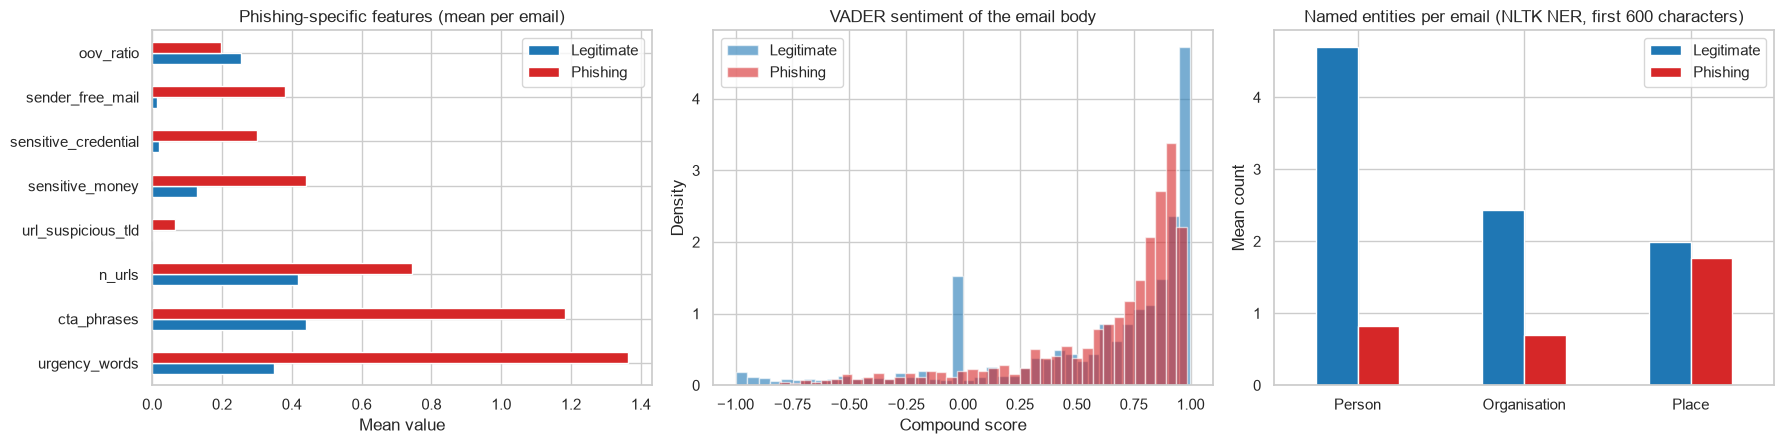

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
feat_view = ["urgency_words", "cta_phrases", "n_urls", "url_suspicious_tld", "sensitive_money", "sensitive_credential",
             "sender_free_mail", "oov_ratio"]
m = data.groupby("label")[feat_view].mean().T
m.columns = ["Legitimate", "Phishing"]
m.plot.barh(ax=axes[0], color=["tab:blue", "tab:red"])
axes[0].set(title="Phishing-specific features (mean per email)", xlabel="Mean value")
for lab, color, name in [(0, "tab:blue", "Legitimate"), (1, "tab:red", "Phishing")]:
    axes[1].hist(data.loc[data.label == lab, "sentiment_compound"], bins=40, alpha=0.6, color=color, label=name, density=True)
axes[1].set(title="VADER sentiment of the email body", xlabel="Compound score", ylabel="Density"); axes[1].legend()
ner = data.groupby("label")[["ner_person", "ner_org", "ner_gpe"]].mean().T
ner.columns = ["Legitimate", "Phishing"]; ner.index = ["Person", "Organisation", "Place"]
ner.plot.bar(ax=axes[2], rot=0, color=["tab:blue", "tab:red"])
axes[2].set(title="Named entities per email (NLTK NER, first 600 characters)", ylabel="Mean count")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_features.png", dpi=200); plt.show()

## Step 2 · NLP model development and training

**Features.** TF-IDF over stemmed unigrams and bigrams (n-grams) for text; regular-expression URL features; VADER
sentiment, NER counts and the NER sensitive-information flag, sensitive-information patterns, subject-line and sender-domain
metadata as the remaining engineered features.

**Models.** Naive Bayes (text only, baseline); a linear SVM on text plus all engineered features; a Random Forest on the
engineered features; and a **stacked ensemble** whose three specialists each see one view of the email (text, URLs,
metadata/linguistics) and whose logistic-regression combiner learns how much to trust each. All tuning uses **stratified
5-fold cross-validation on the training set only**, selecting on PR-AUC, and the final threshold is set on out-of-fold
predictions to catch **at least 99% of phishing** (missing phishing costs more than a false alarm).

In [9]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"precision": "precision", "recall": "recall", "f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc"}

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000, sublinear_tf=True)

def make_views(eng, url_cols, meta_cols):
    return (ColumnTransformer([("tfidf", tfidf(), "text")]), ColumnTransformer([("url", "passthrough", url_cols)]),
            ColumnTransformer([("meta", StandardScaler(), meta_cols)]),
            ColumnTransformer([("tfidf", tfidf(), "text"), ("eng", StandardScaler(), eng)]))

def train_suite(X_tr, y_tr, eng, url_cols, meta_cols):
    text_view, url_view, meta_view, all_view = make_views(eng, url_cols, meta_cols)
    candidates = {
        "Naive Bayes (baseline)": (Pipeline([("x", text_view), ("clf", MultinomialNB())]), {"clf__alpha": [0.01, 0.1, 0.5, 1.0]}),
        "Linear SVM": (Pipeline([("x", all_view), ("clf", CalibratedClassifierCV(LinearSVC(dual="auto"), cv=3))]),
                       {"clf__estimator__C": [0.1, 1.0, 10.0]}),
        "Random Forest": (Pipeline([("x", ColumnTransformer([("eng", "passthrough", eng)])),
                                    ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
                          {"clf__max_depth": [None, 12], "clf__min_samples_leaf": [1, 3]})}
    searches, rows = {}, []
    for name, (pipe, grid) in candidates.items():
        gs = GridSearchCV(pipe, grid, scoring=SCORING, refit="pr_auc", cv=CV, n_jobs=-1).fit(X_tr, y_tr)
        searches[name] = gs
        i, r = gs.best_index_, gs.cv_results_
        rows.append({"model": name, "best params": {k.split("__")[-1]: v for k, v in gs.best_params_.items()},
                     **{f"CV {m}": f"{r[f'mean_test_{m}'][i]:.4f} ± {r[f'std_test_{m}'][i]:.4f}" for m in SCORING}})
    tv, uv, mv, _ = make_views(eng, url_cols, meta_cols)
    ens = StackingClassifier(
        estimators=[("text", Pipeline([("x", tv), ("clf", CalibratedClassifierCV(LinearSVC(dual="auto"), cv=3))])),
                    ("url", Pipeline([("x", uv), ("clf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))])),
                    ("meta", Pipeline([("x", mv), ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]))],
        final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba", n_jobs=-1)
    oof = cross_val_predict(ens, X_tr, y_tr, cv=CV, method="predict_proba", n_jobs=1)[:, 1]
    pred = (oof >= 0.5).astype(int)
    rows.append({"model": "Stacked ensemble", "best params": "—",
                 "CV precision": f"{precision_score(y_tr, pred):.4f}", "CV recall": f"{recall_score(y_tr, pred):.4f}",
                 "CV f1": f"{f1_score(y_tr, pred):.4f}", "CV pr_auc": f"{average_precision_score(y_tr, oof):.4f}",
                 "CV roc_auc": f"{roc_auc_score(y_tr, oof):.4f}"})
    ens.fit(X_tr, y_tr)
    p_, r_, t_ = precision_recall_curve(y_tr, oof)
    thr = float(t_[np.where(r_[:-1] >= 0.99)[0].max()])
    models = {n: gs.best_estimator_ for n, gs in searches.items()}
    models["Stacked ensemble"] = ens
    return models, searches, ens, thr, pd.DataFrame(rows).set_index("model")

def scores(y_true, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred), "PR-AUC": average_precision_score(y_true, p), "ROC-AUC": roc_auc_score(y_true, p),
            "missed phishing": int(fn), "false alarms": int(fp)}

### 2.1 Train the models on Enron vs synthetic phishing

In [10]:
t0 = time.time()
X_train, X_test, y_train, y_test = train_test_split(data, data.label.values, test_size=0.2, stratify=data.label, random_state=SEED)
models, searches, ensemble, THRESHOLD, cv_table = train_suite(X_train, y_train, ENG, URL_COLS, META_COLS)
weights = pd.Series(ensemble.final_estimator_.coef_[0], index=["Text model", "URL model", "Metadata model"])
print(f"Trained on {len(X_train):,} emails in {time.time() - t0:.0f}s")
print(f"High-recall threshold (≥ 99% recall on out-of-fold training predictions): {THRESHOLD:.3f}")
print("Combiner weights:", weights.round(2).to_dict())
cv_table

Trained on 11,699 emails in 43s
High-recall threshold (≥ 99% recall on out-of-fold training predictions): 0.996
Combiner weights: {'Text model': 6.69, 'URL model': 1.76, 'Metadata model': 6.21}


,best params,CV precision,CV recall,CV f1,CV pr_auc,CV roc_auc
model,,,,,,
Naive Bayes (baseline),{'alpha': 0.01},1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000,1.0000 ± 0.0000
Linear SVM,{'C': 10.0},0.9995 ± 0.0007,1.0000 ± 0.0000,0.9997 ± 0.0003,1.0000 ± 0.0000,1.0000 ± 0.0000
Random Forest,"{'max_depth': 12, 'min_samples_leaf': 1}",0.9993 ± 0.0003,1.0000 ± 0.0000,0.9997 ± 0.0002,1.0000 ± 0.0000,1.0000 ± 0.0000
Stacked ensemble,—,1.0000,1.0000,1.0000,1.0000,1.0000


## Step 3 · Phishing pattern analysis and evaluation

### 3.1 Test-set performance

In [11]:
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
test_table = pd.DataFrame({n: scores(y_test, p) for n, p in proba.items()}).T
test_table.loc["Stacked ensemble @ high-recall threshold"] = scores(y_test, proba["Stacked ensemble"], THRESHOLD)
test_table.round(4)

,precision,recall,F1,PR-AUC,ROC-AUC,missed phishing,false alarms
Naive Bayes (baseline),1.0000,1.0000,1.0000,1.0,1.0,0.0,0.0
Linear SVM,0.9993,1.0000,0.9997,1.0,1.0,0.0,1.0
Random Forest,0.9993,1.0000,0.9997,1.0,1.0,0.0,1.0
Stacked ensemble,1.0000,1.0000,1.0000,1.0,1.0,0.0,0.0
Stacked ensemble @ high-recall threshold,1.0000,0.9966,0.9983,1.0,1.0,5.0,0.0


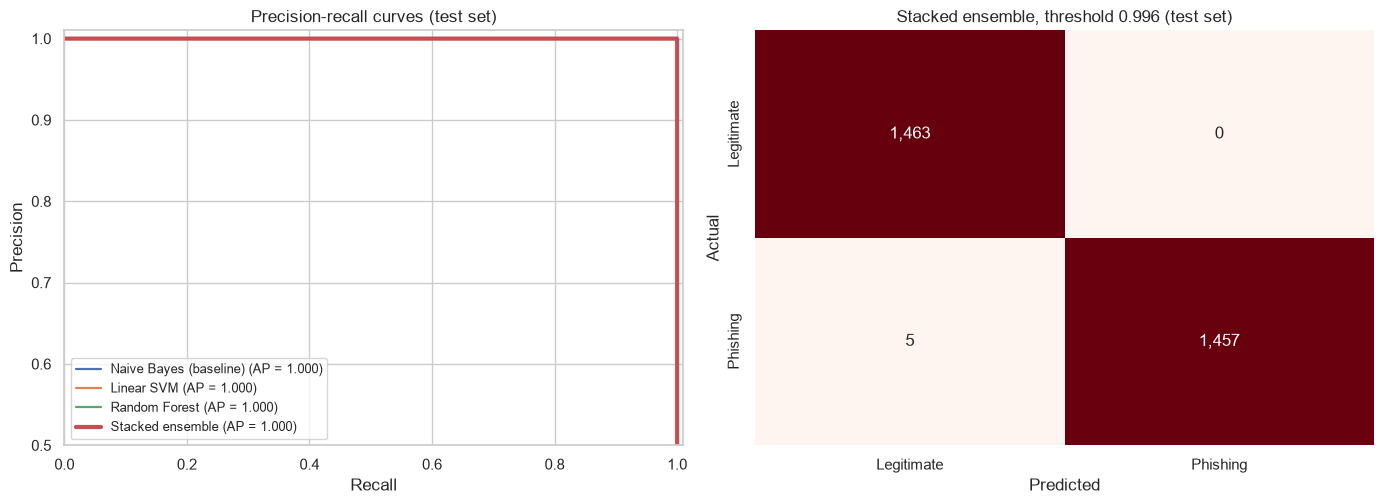

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for name, p in proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rc, pr, lw=3 if name == "Stacked ensemble" else 1.6, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
axes[0].set(title="Precision-recall curves (test set)", xlabel="Recall", ylabel="Precision", xlim=(0, 1.01), ylim=(0.5, 1.01))
axes[0].legend(loc="lower left", fontsize=9)
cm = confusion_matrix(y_test, (proba["Stacked ensemble"] >= THRESHOLD).astype(int))
sns.heatmap(cm, annot=np.array([[f"{v:,}" for v in r] for r in cm]), fmt="", cmap="Reds", cbar=False, ax=axes[1],
            xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"])
axes[1].set(title=f"Stacked ensemble, threshold {THRESHOLD:.3f} (test set)", xlabel="Predicted", ylabel="Actual")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_evaluation.png", dpi=200); plt.show()

### 3.2 Test on real-world phishing examples

The same trained models score the 1,000 real phishing emails. Recall here shows how well training on synthetic phishing
carries over to real attacks.

In [13]:
real_rows = []
for name, m in models.items():
    p_r = m.predict_proba(real_test)[:, 1]
    real_rows.append({"model": name, "real phishing caught @ 0.5": float((p_r >= 0.5).mean()), "median risk score": float(np.median(p_r))})
real_table = pd.DataFrame(real_rows).set_index("model")
p_real = ensemble.predict_proba(real_test)[:, 1]
real_table.loc["Stacked ensemble @ high-recall threshold"] = {"real phishing caught @ 0.5": float((p_real >= THRESHOLD).mean()),
                                                               "median risk score": float(np.median(p_real))}
real_table = real_table.rename(columns={"real phishing caught @ 0.5": "real phishing caught"})
real_recall = float((p_real >= THRESHOLD).mean())
synthetic_recall = float(test_table.loc["Stacked ensemble @ high-recall threshold", "recall"])
print(f"Stacked ensemble at its high-recall threshold: {synthetic_recall:.1%} of synthetic test phishing caught, "
      f"{real_recall:.1%} of real-world phishing caught")
real_table.round(4)

Stacked ensemble at its high-recall threshold: 99.7% of synthetic test phishing caught, 0.0% of real-world phishing caught


,real phishing caught,median risk score
model,,
Naive Bayes (baseline),0.001,0.0000
Linear SVM,0.000,0.0001
Random Forest,0.000,0.0067
Stacked ensemble,0.000,0.0012
Stacked ensemble @ high-recall threshold,0.000,0.0012


In [14]:
COMPARE = ["body_words", "subject_len", "sender_digit_or_hyphen", "n_urls", "urgency_words", "cta_phrases", "caps_ratio",
           "ner_person", "oov_ratio"]
profile = pd.DataFrame({"Enron (legitimate)": X_test[y_test == 0][COMPARE].mean(),
                        "Synthetic phishing": X_test[y_test == 1][COMPARE].mean(),
                        "Real-world phishing": real_test[COMPARE].mean()}).round(3)
print("Why the models do not transfer: average feature values by source")
profile

Why the models do not transfer: average feature values by source


,Enron (legitimate),Synthetic phishing,Real-world phishing
body_words,205.617,51.105,142.030
subject_len,29.836,28.417,0.000
sender_digit_or_hyphen,0.010,0.624,0.000
n_urls,0.410,0.757,0.264
urgency_words,0.383,1.327,0.406
cta_phrases,0.461,1.182,0.664
caps_ratio,0.053,0.002,0.012
ner_person,4.835,0.821,0.422
oov_ratio,0.256,0.201,0.260


### 3.3 Top phishing indicators

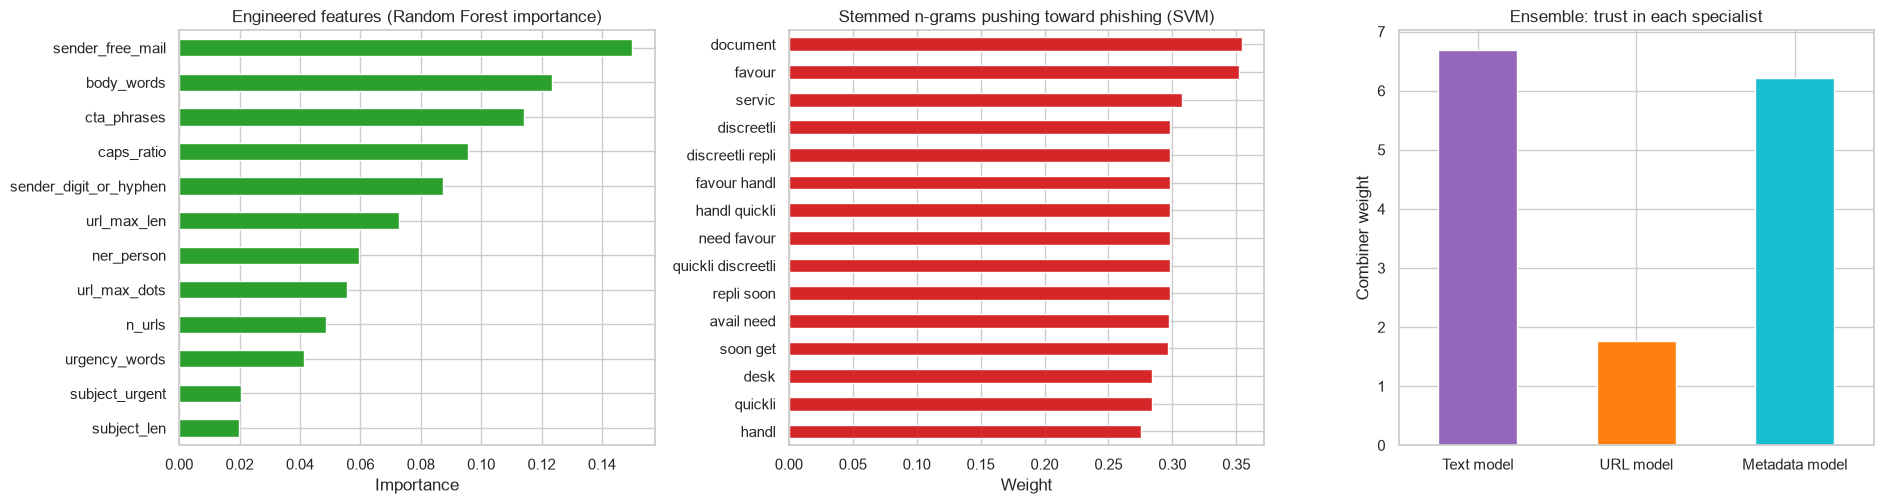

Strongest legitimate-side terms: charl, might, see, think, numtoken th, th, yahoo, eca, breaker, free


In [15]:
rf = searches["Random Forest"].best_estimator_.named_steps["clf"]
rf_imp = pd.Series(rf.feature_importances_, index=ENG).sort_values(ascending=False)
svm_pipe = searches["Linear SVM"].best_estimator_
vocab = svm_pipe.named_steps["x"].named_transformers_["tfidf"].get_feature_names_out()
coef = np.mean([c.estimator.coef_[0] for c in svm_pipe.named_steps["clf"].calibrated_classifiers_], axis=0)
text_coef = pd.Series(coef[:len(vocab)], index=vocab)
top_phish_terms = text_coef[[not set(t.split()) & {"numtoken", "urltoken"} for t in text_coef.index]].nlargest(15)
top_legit_terms = text_coef.nsmallest(10)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
rf_imp.head(12)[::-1].plot.barh(ax=axes[0], color="tab:green")
axes[0].set(title="Engineered features (Random Forest importance)", xlabel="Importance")
top_phish_terms[::-1].plot.barh(ax=axes[1], color="tab:red")
axes[1].set(title="Stemmed n-grams pushing toward phishing (SVM)", xlabel="Weight")
weights.plot.bar(ax=axes[2], rot=0, color=["tab:purple", "tab:orange", "tab:cyan"])
axes[2].set(title="Ensemble: trust in each specialist", ylabel="Combiner weight")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_indicators.png", dpi=200); plt.show()
print("Strongest legitimate-side terms:", ", ".join(top_legit_terms.index))

### 3.4 Phishing detection dashboard with explanations

Each email gets a **risk score** from the stacked ensemble and a plain-language **explanation** taken from the model itself:
the specialist with the largest contribution (combiner weight × that specialist's probability), the words in this email that
pushed the ensemble's text specialist toward phishing (TF-IDF weight × coefficient), and the phishing indicators present.
Emails below the threshold are explained by the words that pushed them toward legitimate instead.

In [16]:
REASONS = {"urgency_words": "urgent language", "cta_phrases": "call-to-action phrases", "url_suspicious_tld": "suspicious URL domain",
           "url_has_ip": "IP-address link", "url_shortener": "shortened link", "url_hyphen_host": "hyphenated link domain",
           "sensitive_money": "money amount", "sensitive_credential": "asks for credentials", "ner_sensitive": "named party + sensitive term",
           "sender_free_mail": "free-webmail sender", "sender_digit_or_hyphen": "lookalike sender domain",
           "sender_suspicious_tld": "sender uses a suspicious domain"}
PLACEHOLDERS = {"numtoken", "urltoken"}
text_est = ensemble.named_estimators_["text"]
text_vocab = text_est.named_steps["x"].named_transformers_["tfidf"].get_feature_names_out()
text_w = np.mean([c.estimator.coef_[0] for c in text_est.named_steps["clf"].calibrated_classifiers_], axis=0)
SPECIALIST = {"text": "Text", "url": "URL", "meta": "Metadata"}

def explain(row, score):
    x = row.to_frame().T
    probs = np.array([est.predict_proba(x)[0, 1] for est in ensemble.named_estimators_.values()])
    contrib = dict(zip(ensemble.named_estimators_, ensemble.final_estimator_.coef_[0] * probs))
    driver = max(contrib, key=contrib.get)
    vec = text_est.named_steps["x"].transform(x).tocoo()
    term_score = {text_vocab[j]: v * text_w[j] for j, v in zip(vec.col, vec.data)}
    if score < THRESHOLD:
        legit = [t for t, v in sorted(term_score.items(), key=lambda kv: kv[1]) if v < 0 and not set(t.split()) & PLACEHOLDERS][:3]
        return "no strong phishing signal" + (f"; legitimate-sounding words: {', '.join(legit)}" if legit else "")
    terms = [t for t, v in sorted(term_score.items(), key=lambda kv: -kv[1]) if v > 0 and not set(t.split()) & PLACEHOLDERS][:3]
    fired = [label for col, label in REASONS.items() if row[col] > 0]
    parts = [f"largest contribution: {SPECIALIST[driver]} model"]
    if terms: parts.append("phishing words: " + ", ".join(terms))
    if fired: parts.append("indicators: " + ", ".join(fired[:3]))
    return "; ".join(parts)

def risk_band(p):
    return "HIGH" if p >= 0.8 else ("MEDIUM" if p >= THRESHOLD else "LOW")

demo = pd.concat([X_test[y_test == 1].sample(3, random_state=SEED), X_test[y_test == 0].sample(3, random_state=SEED),
                  real_test.sample(4, random_state=SEED)])
demo_scores = ensemble.predict_proba(demo)[:, 1]
dashboard = pd.DataFrame({
    "source": ["Synthetic phishing"] * 3 + ["Enron (legitimate)"] * 3 + ["Real-world phishing"] * 4,
    "subject / start of email": [(s if s else b)[:55] for s, b in zip(demo.subject, demo.body)],
    "risk score": demo_scores.round(3), "risk": [risk_band(p) for p in demo_scores],
    "why": [explain(r, sc) for (_, r), sc in zip(demo.iterrows(), demo_scores)]})
display(dashboard.style.background_gradient(subset=["risk score"], cmap="Reds", vmin=0, vmax=1).hide(axis="index"))

source,subject / start of email,risk score,risk,why
Synthetic phishing,Action needed to release your package,0.999000,HIGH,"largest contribution: Text model; phishing words: packag, attempt, account; indicators: call-to-action phrases, money amount, asks for credentials"
Synthetic phishing,New secure document waiting,0.999000,HIGH,"largest contribution: Text model; phishing words: document, secur document, secur; indicators: urgent language, call-to-action phrases, asks for credentials"
Synthetic phishing,Quick favour,0.998000,HIGH,"largest contribution: Text model; phishing words: hello, keep, gift card; indicators: urgent language, asks for credentials, free-webmail sender"
Enron (legitimate),Called the number you gave me about 7:40 PM but it was,0.001000,LOW,"no strong phishing signal; legitimate-sounding words: hope, call, number"
Enron (legitimate),Master Termination Log,0.001000,LOW,"no strong phishing signal; legitimate-sounding words: attach, list, transact"
Enron (legitimate),Flexible Spending Accounts,0.002000,LOW,"no strong phishing signal; legitimate-sounding words: question, work, group"
Real-world phishing,WE NEED HELP. We are a 14 year old fortune 500 company,0.001000,LOW,"no strong phishing signal; legitimate-sounding words: go, look, click link"
Real-world phishing,A:link {TEX-DECORATION: none}A:active {TEXT-DECORATION:,0.001000,LOW,"no strong phishing signal; legitimate-sounding words: compani, list, trade"
Real-world phishing,= ? iso - 8859 - 7 ? q ? get _ cial = eds _ over _ nigh,0.001000,LOW,"no strong phishing signal; legitimate-sounding words: go, remov, save"
Real-world phishing,wanna save $ $ on software ? we have all the oem softwa,0.001000,LOW,"no strong phishing signal; legitimate-sounding words: offic, save, price"


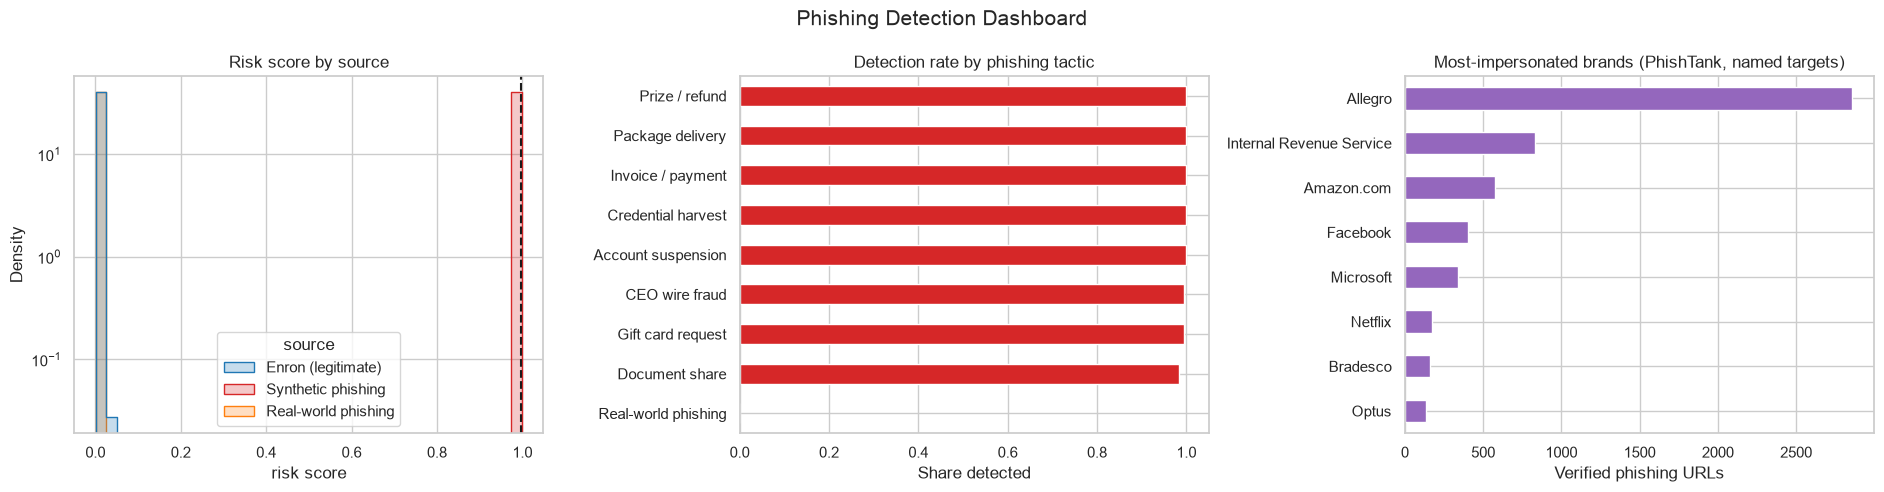

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
score_df = pd.concat([pd.DataFrame({"risk score": proba["Stacked ensemble"][y_test == 0], "source": "Enron (legitimate)"}),
                      pd.DataFrame({"risk score": proba["Stacked ensemble"][y_test == 1], "source": "Synthetic phishing"}),
                      pd.DataFrame({"risk score": p_real, "source": REAL})])
sns.histplot(data=score_df, x="risk score", hue="source", bins=40, stat="density", common_norm=False, element="step", ax=axes[0],
             palette={"Enron (legitimate)": "tab:blue", "Synthetic phishing": "tab:red", REAL: "tab:orange"})
axes[0].axvline(THRESHOLD, color="k", ls="--"); axes[0].set(title="Risk score by source", yscale="log")

tactic_view = X_test.assign(caught=proba["Stacked ensemble"] >= THRESHOLD)[y_test == 1]
detected_tactics = tactic_view.groupby("tactic")["caught"].mean()
rates = pd.concat([detected_tactics, pd.Series({REAL: real_recall})]).sort_values()
rates.plot.barh(ax=axes[1], color=["tab:orange" if t == REAL else "tab:red" for t in rates.index])
axes[1].set(title="Detection rate by phishing tactic", xlabel="Share detected", ylabel="", xlim=(0, 1.05))

brands = phishtank.loc[phishtank.target != "Other", "target"].value_counts().head(8)
if len(brands):
    brands[::-1].plot.barh(ax=axes[2], color="tab:purple")
    axes[2].set(title="Most-impersonated brands (PhishTank, named targets)", xlabel="Verified phishing URLs", ylabel="")
else:                                         # the OpenPhish fallback feed has no target names
    axes[2].text(0.5, 0.5, "No named targets in this feed", ha="center", va="center"); axes[2].axis("off")
fig.suptitle("Phishing Detection Dashboard", fontsize=15)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_dashboard.png", dpi=200); plt.show()

### 3.5 What the real-world phishing looks like

In [18]:
real_eval = real_test.assign(score=p_real, caught=p_real >= THRESHOLD)
print(f"{int(real_eval.caught.sum())} of {len(real_eval):,} real phishing emails were caught at the high-recall threshold.")
print("Examples of real phishing the model missed:")
for t in real_eval[~real_eval.caught].sample(min(4, int((~real_eval.caught).sum())), random_state=SEED).body:
    print(" •", re.sub(r"\s+", " ", t)[:200], "...")

0 of 1,000 real phishing emails were caught at the high-recall threshold.
Examples of real phishing the model missed:
 • WE NEED HELP. We are a 14 year old fortune 500 company, and we have grown 1000%! We cannot keep up. We are looking for individuals who want to work at home, and make a good living.So if you are lookin ...
 • A:link {TEX-DECORATION: none}A:active {TEXT-DECORATION: none}A:visited {TEXT-DECORATION: none}A:hover {COLOR: #0033ff; TEXT-DECORATION: underline} OTC Newsletter Discover Tomorrow's Winners For Immedi ...
 • = ? iso - 8859 - 7 ? q ? get _ cial = eds _ over _ night _ - _ no _ prescription _ needed ? = up to 80 % savings on xanax , valium , phentermine , viagra here for email removal , go here . huck cation ...
 • wanna save $ $ on software ? we have all the oem software at incredibly low prices we have all the leading software you can think of ! windows xp professional and office xp professional for as low as  ...


### 3.6 Threat intelligence summary and security recommendations

In [19]:
https_share = phishtank.url.str.lower().str.startswith("https").mean()
ip_share = phishtank.host.str.fullmatch(r"[\d.]+").mean()
top_tld = phishtank.tld.value_counts().head(6)
short_share = phishtank.host.isin(SHORTENERS).mean()
brand_note = f" The most impersonated named brands are {', '.join(brands.index[:5])}." if len(brands) else ""
ens_test = test_table.loc["Stacked ensemble @ high-recall threshold"]
worst_tactic = detected_tactics.idxmin()
tactic_note = ("Every synthetic attack pattern was detected in the test set." if detected_tactics.min() >= 1.0
               else f"Among the synthetic attack patterns, {worst_tactic} was detected least often ({detected_tactics.min():.1%}).")
display(Markdown(f"""
#### Threat intelligence summary

**1. The phishing infrastructure (PhishTank, {len(phishtank):,} verified live URLs).** {https_share:.0%} of phishing links use HTTPS,
so a padlock says nothing about whether a site is legitimate. {ip_share:.1%} use a raw IP address and {short_share:.1%} a known
shortener or QR-code redirector. The most common top-level domains are {", ".join(f"`.{t}` ({c:,})" for t, c in top_tld.items())}.{brand_note}

**2. Detection.** At a threshold tuned for 99% recall, the stacked ensemble reached recall {ens_test['recall']:.1%} and precision
{ens_test['precision']:.3f} on the synthetic test set. {tactic_note} On **real-world phishing it caught {real_recall:.1%}**: the synthetic
training data did not prepare it for real attacks.

**3. Common phishing tactics detected.** The strongest indicators were {", ".join(f"`{f}`" for f in rf_imp.index[:4])} (Random Forest)
and the n-grams {", ".join(f"`{t}`" for t in top_phish_terms.index[:6])} (linear SVM). In the synthetic training data these point
to free-webmail and lookalike senders, short template-length messages, call-to-action phrasing and CEO-fraud wording; the
real-world test shows such template cues do not carry over to real attacks.

**Recommendations.** (a) Score inbound email and quarantine above the high-recall threshold; (b) sandbox or rewrite links and flag
suspicious top-level domains rather than trusting HTTPS; (c) require call-back verification for any payment, wire or gift-card
request; (d) before deployment, retrain and validate on real, recent phishing reported by users, because a model trained on
synthetic phishing does not transfer to real attacks.
"""))


#### Threat intelligence summary

**1. The phishing infrastructure (PhishTank, 61,047 verified live URLs).** 93% of phishing links use HTTPS,
so a padlock says nothing about whether a site is legitimate. 0.1% use a raw IP address and 4.0% a known
shortener or QR-code redirector. The most common top-level domains are `.com` (24,705), `.de` (4,764), `.app` (4,243), `.me` (3,706), `.to` (3,534), `.dev` (3,305). The most impersonated named brands are Allegro, Internal Revenue Service, Amazon.com, Facebook, Microsoft.

**2. Detection.** At a threshold tuned for 99% recall, the stacked ensemble reached recall 99.7% and precision
1.000 on the synthetic test set. Among the synthetic attack patterns, Document share was detected least often (98.3%). On **real-world phishing it caught 0.0%**: the synthetic
training data did not prepare it for real attacks.

**3. Common phishing tactics detected.** The strongest indicators were `sender_free_mail`, `body_words`, `cta_phrases`, `caps_ratio` (Random Forest)
and the n-grams `document`, `favour`, `servic`, `discreetli`, `discreetli repli`, `favour handl` (linear SVM). In the synthetic training data these point
to free-webmail and lookalike senders, short template-length messages, call-to-action phrasing and CEO-fraud wording; the
real-world test shows such template cues do not carry over to real attacks.

**Recommendations.** (a) Score inbound email and quarantine above the high-recall threshold; (b) sandbox or rewrite links and flag
suspicious top-level domains rather than trusting HTTPS; (c) require call-back verification for any payment, wire or gift-card
request; (d) before deployment, retrain and validate on real, recent phishing reported by users, because a model trained on
synthetic phishing does not transfer to real attacks.


## Findings

In [20]:
nb_real = real_table.loc["Naive Bayes (baseline)", "real phishing caught"]
lo, hi = test_table["PR-AUC"].min(), test_table["PR-AUC"].max()
prauc_text = f"Every model reached a test PR-AUC of {lo:.3f}" if f"{lo:.3f}" == f"{hi:.3f}" else f"Test PR-AUC ranged from {lo:.3f} to {hi:.3f}"
display(Markdown(f"""
**1. The NLP pipeline and features run end to end.** NLTK preprocessing (tokenization, stop-word removal, Porter stemming) fed TF-IDF
unigrams and bigrams, and {len(ENG)} engineered features captured urgency, calls to action, URL tricks, grammar slips, sentiment,
named entities, a NER-based sensitive-information flag, subject lines and sender metadata. Company names, email addresses and
quoted reply headers were deleted so that no model could learn "mentions Enron = safe".

**2. On synthetic phishing, every classifier is near-perfect.** {prauc_text}, and the stacked ensemble caught {synthetic_recall:.1%} of synthetic phishing at its high-recall threshold.

**3. On real-world phishing, it fails.** The same ensemble caught {real_recall:.1%} of 1,000 real phishing emails (Naive Bayes:
{nb_real:.1%}). The feature profile shows why: real phishing is longer than the synthetic phishing, has no subject or sender headers,
and uses far less of the urgency and call-to-action phrasing the templates used; and, as the examples in 3.5 show, much of it
is bulk spam. The models learned the synthetic templates, not phishing.

**4. Signals the ensemble uses.** The combiner weighted the text, URL and metadata specialists {weights['Text model']:.2f},
{weights['URL model']:.2f} and {weights['Metadata model']:.2f}.

**Limitations.** Synthetic phishing as the only phishing training data; Enron mail from 1999–2002; real-world test emails from one
public dataset that is mostly spam and has no headers; and a PhishTank snapshot that changes daily.
"""))


**1. The NLP pipeline and features run end to end.** NLTK preprocessing (tokenization, stop-word removal, Porter stemming) fed TF-IDF
unigrams and bigrams, and 29 engineered features captured urgency, calls to action, URL tricks, grammar slips, sentiment,
named entities, a NER-based sensitive-information flag, subject lines and sender metadata. Company names, email addresses and
quoted reply headers were deleted so that no model could learn "mentions Enron = safe".

**2. On synthetic phishing, every classifier is near-perfect.** Every model reached a test PR-AUC of 1.000, and the stacked ensemble caught 99.7% of synthetic phishing at its high-recall threshold.

**3. On real-world phishing, it fails.** The same ensemble caught 0.0% of 1,000 real phishing emails (Naive Bayes:
0.1%). The feature profile shows why: real phishing is longer than the synthetic phishing, has no subject or sender headers,
and uses far less of the urgency and call-to-action phrasing the templates used; and, as the examples in 3.5 show, much of it
is bulk spam. The models learned the synthetic templates, not phishing.

**4. Signals the ensemble uses.** The combiner weighted the text, URL and metadata specialists 6.69,
1.76 and 6.21.

**Limitations.** Synthetic phishing as the only phishing training data; Enron mail from 1999–2002; real-world test emails from one
public dataset that is mostly spam and has no headers; and a PhishTank snapshot that changes daily.


## Reflection

Modules 1 to 4 were about numbers in network traffic and transactions. This lab was about language, and it showed me that
an attacker's main weapon is often a sentence rather than a payload: urgency, authority and a believable brand. The most
important result was the real-world test. Near-perfect scores on synthetic phishing looked like success, but the model
caught almost none of the real phishing. That is the distribution-shift problem this course keeps returning to: a model is
only as good as the data it learned from. I want to build email defences that are trained and validated on fresh, real
attacks and that explain every verdict, because an employee will only act on a warning they understand.

In [21]:
# Machine-readable summary of this run (used to generate the accompanying PDF report)
SUMMARY = {
    "n_enron_files": n_files, "n_legit": int((data.label == 0).sum()), "n_synth": int((data.label == 1).sum()),
    "n_phishtank": int(len(phishtank)), "n_real_unique": int(len(kag)), "n_real": int(len(real_test)),
    "n_eng": len(ENG), "n_train": int(len(X_train)), "n_test": int(len(X_test)), "threshold": THRESHOLD,
    "test": {m: {k: float(v) for k, v in row.items()} for m, row in test_table.iterrows()},
    "real": {m: {k: float(v) for k, v in row.items()} for m, row in real_table.iterrows()},
    "synthetic_recall": synthetic_recall, "real_recall": real_recall, "weights": weights.round(2).to_dict(),
    "profile": profile.to_dict(), "ner_sensitive": ner_view.to_dict(),
    "top_rf": rf_imp.head(6).round(4).to_dict(), "top_terms": top_phish_terms.head(8).round(3).to_dict(),
    "tactic_detection": detected_tactics.round(4).to_dict(), "worst_tactic_rate": float(detected_tactics.min()),
    "https_share": float(https_share), "ip_share": float(ip_share), "short_share": float(short_share),
    "top_tld": top_tld.to_dict(), "brands": brands.head(5).to_dict(),
}
print(json.dumps(SUMMARY, indent=1, default=str))

{
 "n_enron_files": 517401,
 "n_legit": 7312,
 "n_synth": 7312,
 "n_phishtank": 61047,
 "n_real_unique": 5772,
 "n_real": 1000,
 "n_eng": 29,
 "n_train": 11699,
 "n_test": 2925,
 "threshold": 0.9960885242736284,
 "test": {
  "Naive Bayes (baseline)": {
   "precision": 1.0,
   "recall": 1.0,
   "F1": 1.0,
   "PR-AUC": 1.0,
   "ROC-AUC": 1.0,
   "missed phishing": 0.0,
   "false alarms": 0.0
  },
  "Linear SVM": {
   "precision": 0.9993164730006835,
   "recall": 1.0,
   "F1": 0.9996581196581197,
   "PR-AUC": 1.0,
   "ROC-AUC": 1.0,
   "missed phishing": 0.0,
   "false alarms": 1.0
  },
  "Random Forest": {
   "precision": 0.9993164730006835,
   "recall": 1.0,
   "F1": 0.9996581196581197,
   "PR-AUC": 1.0,
   "ROC-AUC": 1.0,
   "missed phishing": 0.0,
   "false alarms": 1.0
  },
  "Stacked ensemble": {
   "precision": 1.0,
   "recall": 1.0,
   "F1": 1.0,
   "PR-AUC": 0.9999999999999999,
   "ROC-AUC": 1.0,
   "missed phishing": 0.0,
   "false alarms": 0.0
  },
  "Stacked ensemble @ high-re